# Dimensionality Reduction & Unsupervised Clustering
**PCA · K-Means · DBSCAN · Hierarchical Clustering**

**Goal:** Discover hidden patterns in a high-dimensional dataset by first reducing its dimensions with Principal Component Analysis (PCA), and then grouping similar samples using three unsupervised clustering algorithms.

**Dataset:** Breast Cancer Wisconsin (Diagnostic) from `scikit-learn`: 569 samples and **30 numerical features** (cell nucleus measurements). The diagnosis label is *ignored* during clustering and used only at the end to check how well the clusters match reality.

**Workflow**
1. Load and explore the data
2. Standardize features
3. PCA and scree plot, to choose the number of components
4. Interpret the principal components (loadings)
5. K-Means with the Elbow Method and Silhouette analysis
6. DBSCAN
7. Hierarchical (Agglomerative) clustering with a dendrogram
8. Compare all models and draw conclusions

## 1. Setup and Imports

In [1]:
import warnings
warnings.filterwarnings("ignore")

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (silhouette_score, silhouette_samples,
                             davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score)
from scipy.cluster.hierarchy import linkage, dendrogram

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams["figure.dpi"] = 110

os.makedirs("images", exist_ok=True)
def save(name):
    plt.savefig(f"images/{name}.png", bbox_inches="tight", dpi=150)

## 2. Load and Explore the Data

In [2]:
data = load_breast_cancer(as_frame=True)
X = data.data.copy()                         # 30 numerical features
y_true = data.target.copy()                  # used ONLY for final validation
target_names = {0: "malignant", 1: "benign"}

print(f"Samples: {X.shape[0]}  |  Features: {X.shape[1]}")
print(f"Missing values: {X.isna().sum().sum()}")
X.head()

Samples: 569  |  Features: 30
Missing values: 0


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [3]:
X.describe().T[["mean", "std", "min", "max"]].round(2)

,mean,std,min,max
mean radius,14.13,3.52,6.98,28.11
mean texture,19.29,4.30,9.71,39.28
mean perimeter,91.97,24.30,43.79,188.50
mean area,654.89,351.91,143.50,2501.00
mean smoothness,0.10,0.01,0.05,0.16
mean compactness,0.10,0.05,0.02,0.35
mean concavity,0.09,0.08,0.00,0.43
mean concave points,0.05,0.04,0.00,0.20
mean symmetry,0.18,0.03,0.11,0.30
mean fractal dimension,0.06,0.01,0.05,0.10


The features are on very different scales (for example, `area` is in the hundreds or thousands, while `smoothness` is around 0.1). PCA and distance-based clustering are sensitive to scale, so **standardization is essential**.

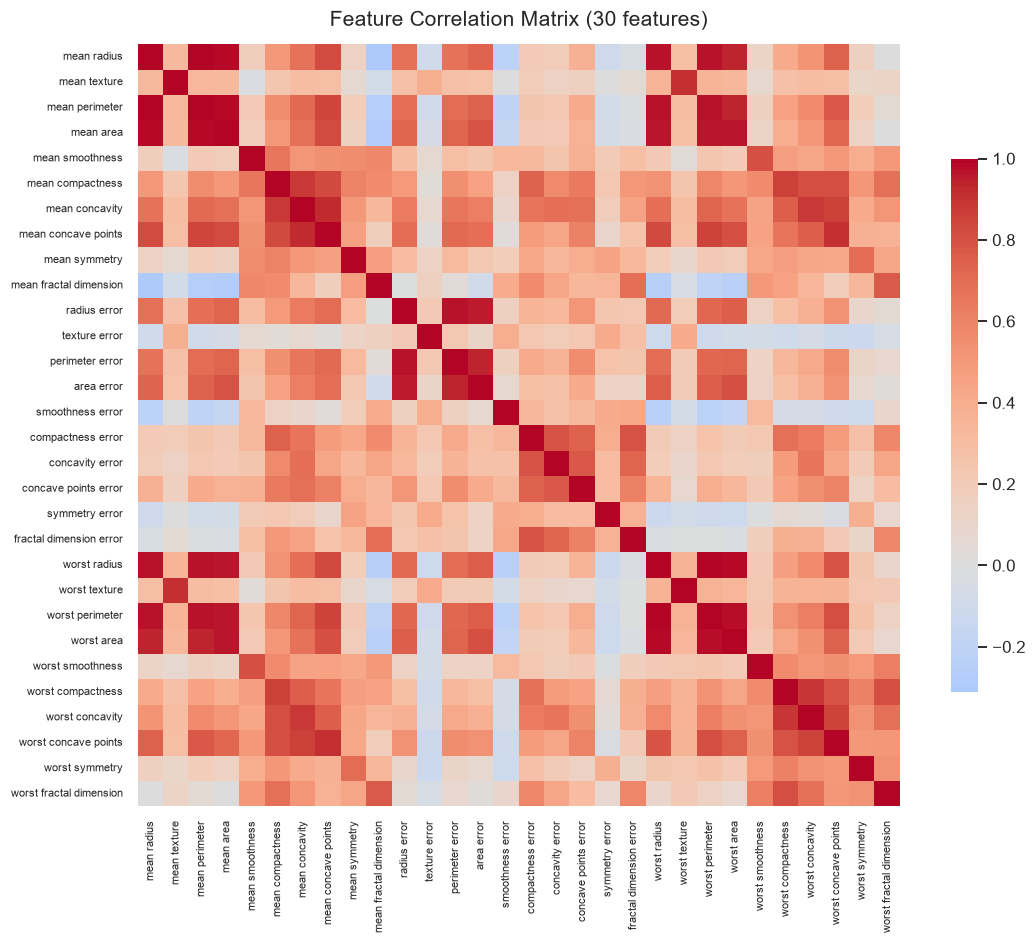

In [4]:
# Correlation heatmap: many features are strongly correlated -> PCA will compress well
plt.figure(figsize=(12, 9))
sns.heatmap(X.corr(), cmap="coolwarm", center=0, square=True,
            cbar_kws={"shrink": .7}, xticklabels=True, yticklabels=True)
plt.title("Feature Correlation Matrix (30 features)", fontsize=14, pad=12)
plt.xticks(fontsize=7); plt.yticks(fontsize=7)
save("01_correlation_heatmap")
plt.show()

## 3. Standardize the Features
Every feature is rescaled to **mean = 0** and **standard deviation = 1**.

In [5]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Mean after scaling (approx 0):", np.round(X_scaled.mean(axis=0)[:5], 6), "...")
print("Std  after scaling (approx 1):", np.round(X_scaled.std(axis=0)[:5], 6), "...")

Mean after scaling (approx 0): [-0. -0. -0. -0.  0.] ...
Std  after scaling (approx 1): [1. 1. 1. 1. 1.] ...


## 4. Principal Component Analysis (PCA)

In [6]:
pca_full = PCA(random_state=RANDOM_STATE).fit(X_scaled)

evr = pca_full.explained_variance_ratio_
cum_evr = np.cumsum(evr)
n_95 = int(np.argmax(cum_evr >= 0.95) + 1)
n_90 = int(np.argmax(cum_evr >= 0.90) + 1)
n_kaiser = int((pca_full.explained_variance_ > 1).sum())

print(f"Components for 90% variance : {n_90}")
print(f"Components for 95% variance : {n_95}")
print(f"Kaiser criterion (eigenvalue > 1): {n_kaiser}")

pd.DataFrame({
    "PC": [f"PC{i+1}" for i in range(10)],
    "Eigenvalue": pca_full.explained_variance_[:10].round(3),
    "Explained Variance %": (evr[:10] * 100).round(2),
    "Cumulative %": (cum_evr[:10] * 100).round(2),
})

Components for 90% variance : 7
Components for 95% variance : 10
Kaiser criterion (eigenvalue > 1): 6


,PC,Eigenvalue,Explained Variance %,Cumulative %
0,PC1,13.305,44.27,44.27
1,PC2,5.701,18.97,63.24
2,PC3,2.823,9.39,72.64
3,PC4,1.984,6.60,79.24
4,PC5,1.652,5.50,84.73
5,PC6,1.209,4.02,88.76
6,PC7,0.676,2.25,91.01
7,PC8,0.477,1.59,92.60
8,PC9,0.418,1.39,93.99
9,PC10,0.351,1.17,95.16


### 4.1 Scree Plot: Explained Variance Ratio

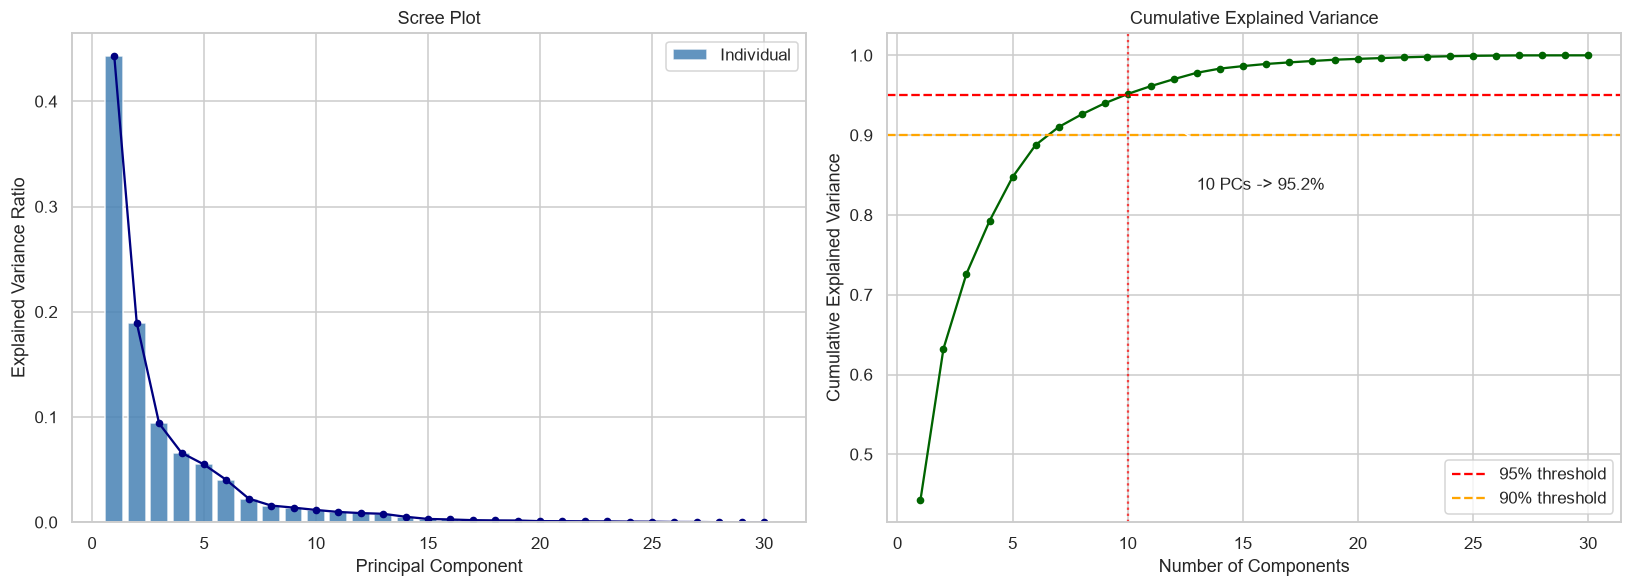

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
pcs = np.arange(1, len(evr) + 1)

# Left: scree plot
ax[0].bar(pcs, evr, color="steelblue", alpha=0.85, label="Individual")
ax[0].plot(pcs, evr, "o-", color="navy", ms=4)
ax[0].set_xlabel("Principal Component"); ax[0].set_ylabel("Explained Variance Ratio")
ax[0].set_title("Scree Plot"); ax[0].legend()

# Right: cumulative variance
ax[1].plot(pcs, cum_evr, "o-", color="darkgreen", ms=4)
ax[1].axhline(0.95, color="red", ls="--", label="95% threshold")
ax[1].axhline(0.90, color="orange", ls="--", label="90% threshold")
ax[1].axvline(n_95, color="red", ls=":", alpha=.7)
ax[1].annotate(f"{n_95} PCs -> {cum_evr[n_95-1]*100:.1f}%", xy=(n_95, cum_evr[n_95-1]),
               xytext=(n_95 + 3, cum_evr[n_95-1] - 0.12),
               arrowprops=dict(arrowstyle="->"), fontsize=11)
ax[1].set_xlabel("Number of Components"); ax[1].set_ylabel("Cumulative Explained Variance")
ax[1].set_title("Cumulative Explained Variance"); ax[1].legend(loc="lower right")
plt.tight_layout()
save("02_pca_scree_plot")
plt.show()

**Decision:** The first few components capture most of the information. We keep the number of components that explain **at least 95%** of the variance (`n_95`). This reduces 30 dimensions to far fewer while losing almost no information, and it also removes noise before clustering.

In [8]:
pca = PCA(n_components=n_95, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)
print(f"Reduced shape: {X_scaled.shape} -> {X_pca.shape}")
print(f"Variance retained: {pca.explained_variance_ratio_.sum()*100:.2f}%")

pc_cols = [f"PC{i+1}" for i in range(X_pca.shape[1])]
df_pca = pd.DataFrame(X_pca, columns=pc_cols)

Reduced shape: (569, 30) -> (569, 10)
Variance retained: 95.16%


### 4.2 Interpreting the Principal Components (Loadings)

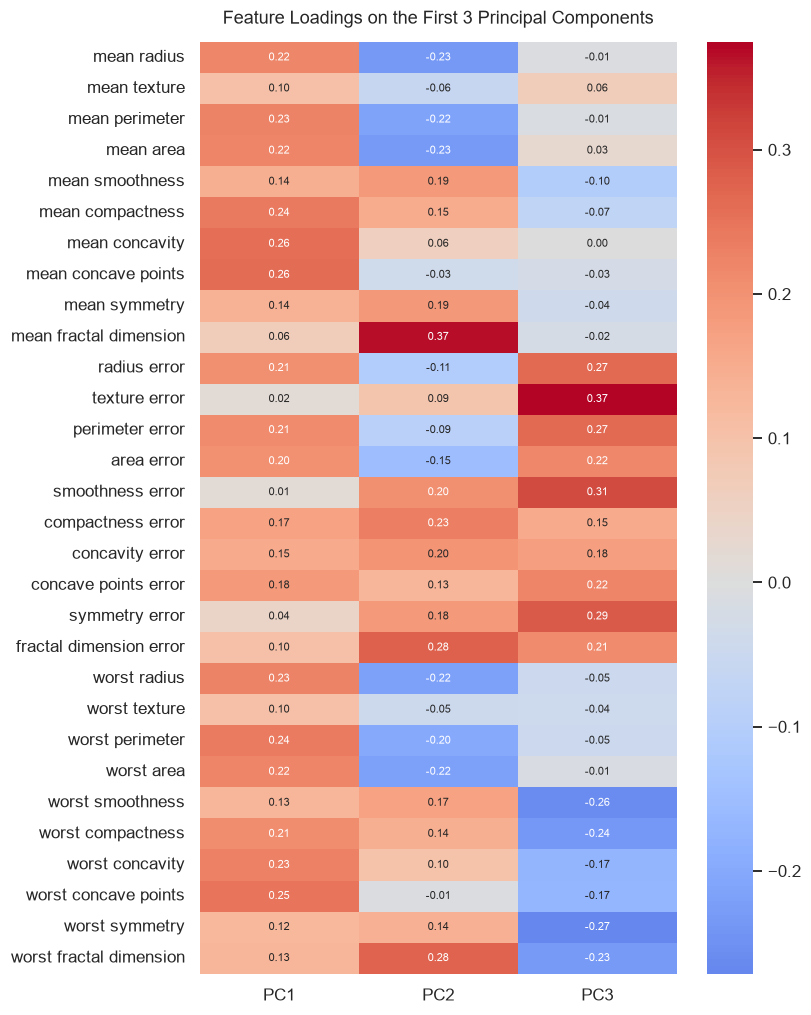

Top contributing features to PC1:
mean concave points     0.261
mean concavity          0.258
worst concave points    0.251
mean compactness        0.239
worst perimeter         0.237
Name: PC1, dtype: float64


In [9]:
loadings = pd.DataFrame(pca.components_[:3].T, index=X.columns, columns=["PC1", "PC2", "PC3"])

plt.figure(figsize=(7, 11))
sns.heatmap(loadings, cmap="coolwarm", center=0, annot=True, fmt=".2f", annot_kws={"size": 7})
plt.title("Feature Loadings on the First 3 Principal Components", pad=12)
save("03_pca_loadings")
plt.show()

print("Top contributing features to PC1:")
print(loadings["PC1"].abs().sort_values(ascending=False).head(5).round(3))

**Reading the loadings:** PC1 is dominated by size-related features (radius, perimeter, area, concavity). It acts as an overall *"tumor size and irregularity"* axis. PC2 mainly captures texture and fractal-dimension related features.

### 4.3 PCA Projection Coloured by the True Diagnosis (for reference only)

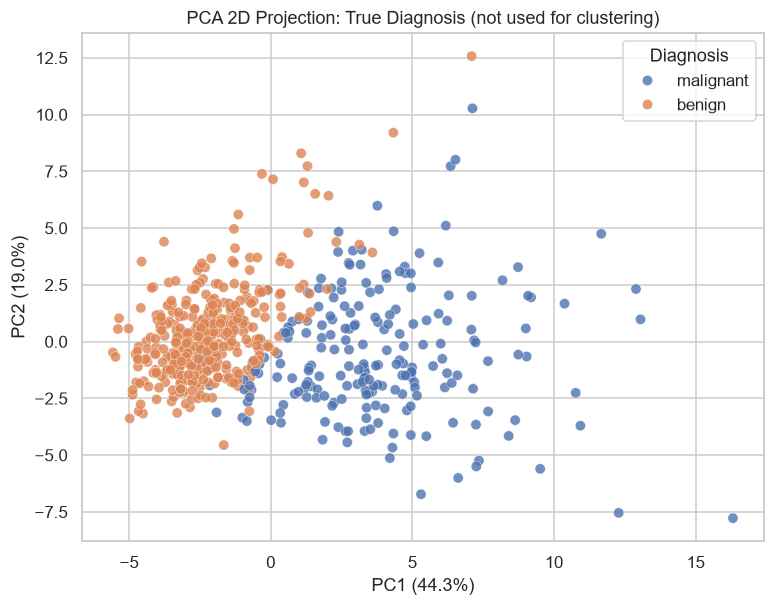

In [10]:
df_vis = df_pca[["PC1", "PC2", "PC3"]].copy()
df_vis["Diagnosis"] = y_true.map(target_names).values

plt.figure(figsize=(8, 6))
sns.scatterplot(data=df_vis, x="PC1", y="PC2", hue="Diagnosis", s=45, alpha=.8, edgecolor="white", linewidth=.3)
plt.xlabel(f"PC1 ({evr[0]*100:.1f}%)"); plt.ylabel(f"PC2 ({evr[1]*100:.1f}%)")
plt.title("PCA 2D Projection: True Diagnosis (not used for clustering)")
save("04_pca_2d_true_labels")
plt.show()

## 5. K-Means Clustering
### 5.1 Finding the Optimal k: Elbow Method and Silhouette Score

In [11]:
k_range = range(2, 11)
inertias, sil_scores, db_scores, ch_scores = [], [], [], []

for k in k_range:
    km = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit(X_pca)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_pca, km.labels_))
    db_scores.append(davies_bouldin_score(X_pca, km.labels_))
    ch_scores.append(calinski_harabasz_score(X_pca, km.labels_))

k_metrics = pd.DataFrame({"k": list(k_range), "Inertia (WCSS)": inertias,
                          "Silhouette": sil_scores, "Davies-Bouldin": db_scores,
                          "Calinski-Harabasz": ch_scores}).round(4)
k_metrics

,k,Inertia (WCSS),Silhouette,Davies-Bouldin,Calinski-Harabasz
0,2,10770.2900,0.3580,1.2597,288.1246
1,3,9239.0996,0.3265,1.4571,214.5429
2,4,8450.0552,0.2861,1.4180,173.6940
3,5,7744.4470,0.1730,1.6642,154.7348
4,6,7175.8555,0.1783,1.6386,142.2816
5,7,6742.6411,0.1693,1.5723,131.9799
6,8,6367.7838,0.1714,1.4721,124.2898
7,9,6038.3150,0.1630,1.4307,118.3025
8,10,5827.6206,0.1633,1.4307,111.0107


Elbow method suggests k = 5
Best Silhouette score at k = 2  (score = 0.3580)


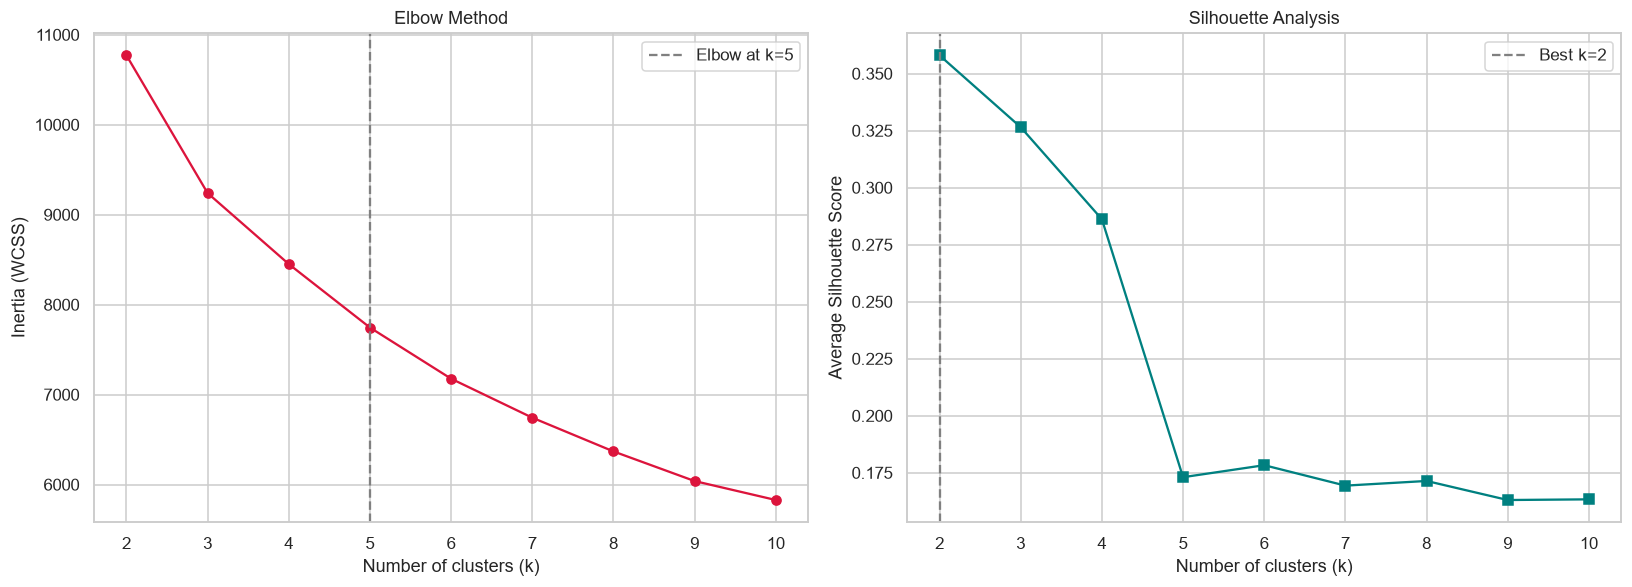

In [12]:
best_k = int(k_metrics.loc[k_metrics["Silhouette"].idxmax(), "k"])

# Automatic elbow detection: the point farthest from the line joining first and last points
kk = np.array(list(k_range)); ii = np.array(inertias)
p1, p2 = np.array([kk[0], ii[0]]), np.array([kk[-1], ii[-1]])
d = p2 - p1
dists = [abs(d[0] * (p1[1] - i) - d[1] * (p1[0] - k)) / np.linalg.norm(d) for k, i in zip(kk, ii)]
elbow_k = int(kk[int(np.argmax(dists))])
print(f"Elbow method suggests k = {elbow_k}")
print(f"Best Silhouette score at k = {best_k}  (score = {max(sil_scores):.4f})")

fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
ax[0].plot(kk, inertias, "o-", color="crimson")
ax[0].axvline(elbow_k, color="gray", ls="--", label=f"Elbow at k={elbow_k}")
ax[0].set_xlabel("Number of clusters (k)"); ax[0].set_ylabel("Inertia (WCSS)")
ax[0].set_title("Elbow Method"); ax[0].legend()

ax[1].plot(kk, sil_scores, "s-", color="teal")
ax[1].axvline(best_k, color="gray", ls="--", label=f"Best k={best_k}")
ax[1].set_xlabel("Number of clusters (k)"); ax[1].set_ylabel("Average Silhouette Score")
ax[1].set_title("Silhouette Analysis"); ax[1].legend()
plt.tight_layout()
save("05_kmeans_elbow_silhouette")
plt.show()

**Decision:** The elbow curve bends gradually, so the elbow alone is ambiguous (the automatic detector suggests k = 5). The Silhouette score is much clearer: it is highest at **k = 2**, meaning two well-separated groups. We choose **k = 2**, which is also consistent with the structure seen in the PCA projection.

### 5.2 Silhouette Plot for the Chosen k

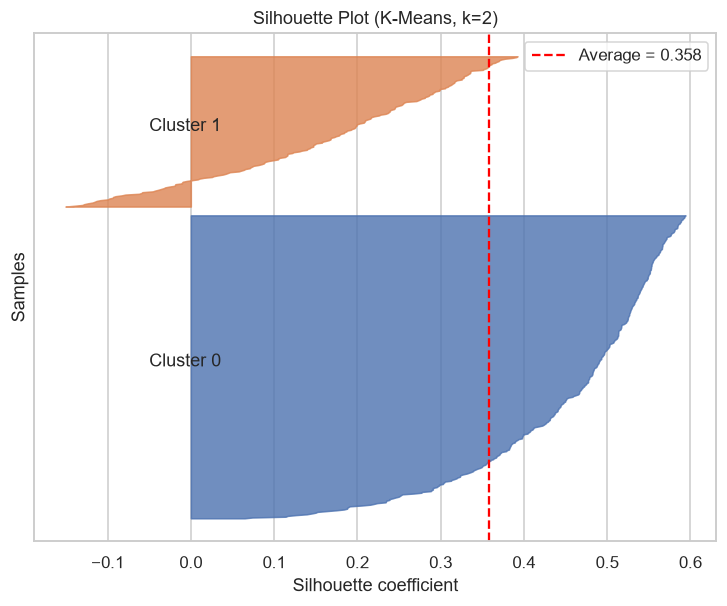

In [13]:
km_final = KMeans(n_clusters=best_k, n_init=20, random_state=RANDOM_STATE).fit(X_pca)
km_labels = km_final.labels_
sample_sil = silhouette_samples(X_pca, km_labels)

fig, ax = plt.subplots(figsize=(8, 6))
y_lower = 10
colors = sns.color_palette("deep", best_k)
for c in range(best_k):
    vals = np.sort(sample_sil[km_labels == c])
    y_upper = y_lower + len(vals)
    ax.fill_betweenx(np.arange(y_lower, y_upper), 0, vals, color=colors[c], alpha=.8)
    ax.text(-0.05, y_lower + 0.5 * len(vals), f"Cluster {c}")
    y_lower = y_upper + 10
ax.axvline(sil_scores[best_k - 2], color="red", ls="--", label=f"Average = {sil_scores[best_k-2]:.3f}")
ax.set_xlabel("Silhouette coefficient"); ax.set_ylabel("Samples")
ax.set_yticks([]); ax.set_title(f"Silhouette Plot (K-Means, k={best_k})"); ax.legend()
save("06_kmeans_silhouette_plot")
plt.show()

### 5.3 K-Means Cluster Visualization (2D with Seaborn, 3D with Plotly)

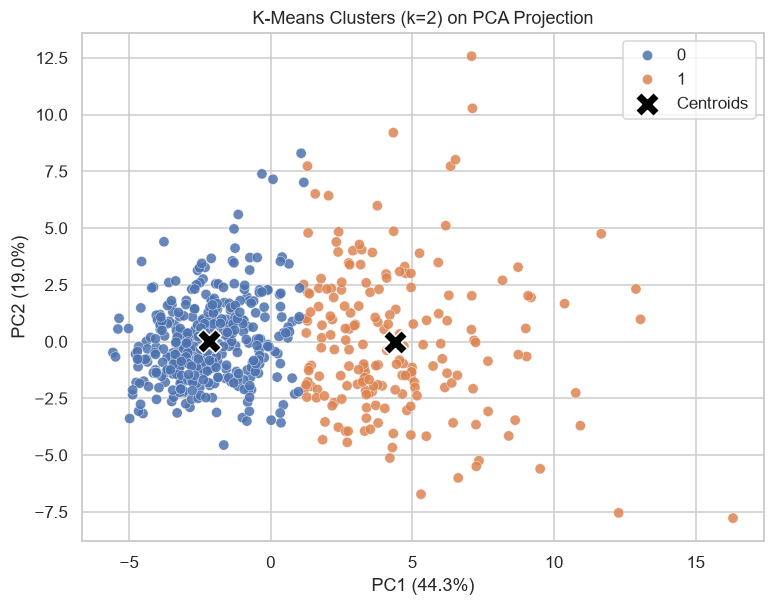

In [14]:
df_vis["KMeans"] = pd.Categorical(km_labels.astype(str))

fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(data=df_vis, x="PC1", y="PC2", hue="KMeans", s=45, alpha=.85,
                edgecolor="white", linewidth=.3, ax=ax)
centers = km_final.cluster_centers_
ax.scatter(centers[:, 0], centers[:, 1], c="black", marker="X", s=250, label="Centroids", edgecolor="white")
ax.set_xlabel(f"PC1 ({evr[0]*100:.1f}%)"); ax.set_ylabel(f"PC2 ({evr[1]*100:.1f}%)")
ax.set_title(f"K-Means Clusters (k={best_k}) on PCA Projection"); ax.legend()
save("07_kmeans_2d")
plt.show()

In [15]:
fig3d = px.scatter_3d(df_vis, x="PC1", y="PC2", z="PC3", color="KMeans",
                      title=f"K-Means Clusters (k={best_k}): Interactive 3D PCA Projection",
                      opacity=0.8, height=650)
fig3d.update_traces(marker=dict(size=4))
fig3d.show()

## 6. DBSCAN (Density-Based Clustering)
DBSCAN needs two parameters: `eps` (neighbourhood radius) and `min_samples`. It can find arbitrarily shaped clusters and labels outliers as **noise (-1)**.

### 6.1 Choosing eps with the k-distance plot

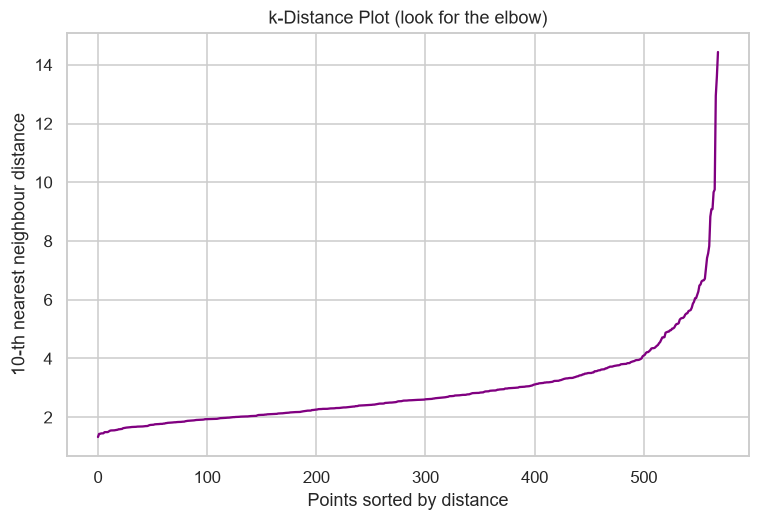

In [16]:
min_samples = 2 * X_pca.shape[1] if X_pca.shape[1] < 10 else 10   # rule of thumb
nn = NearestNeighbors(n_neighbors=min_samples).fit(X_pca)
distances, _ = nn.kneighbors(X_pca)
k_dist = np.sort(distances[:, -1])

plt.figure(figsize=(8, 5))
plt.plot(k_dist, color="purple")
plt.xlabel("Points sorted by distance"); plt.ylabel(f"{min_samples}-th nearest neighbour distance")
plt.title("k-Distance Plot (look for the elbow)")
save("08_dbscan_k_distance")
plt.show()

### 6.2 Sweeping eps
We sweep `eps` and record how many clusters appear and how much data is labelled as noise. A good DBSCAN setting usually shows a *stable plateau*. Here, small `eps` values mark most points as noise, while larger values merge everything into **one** dense cluster. That tells us the two diagnosis groups are **not separated by a density gap**, so DBSCAN is best used here as an **outlier detector**.

In [17]:
rows = []
for eps in np.arange(1.5, 6.1, 0.5):
    lab = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X_pca)
    n_clusters = len(set(lab)) - (1 if -1 in lab else 0)
    rows.append({"eps": round(eps, 2), "min_samples": min_samples, "clusters": n_clusters,
                 "noise points": int((lab == -1).sum()), "noise %": round((lab == -1).mean() * 100, 1)})
db_sweep = pd.DataFrame(rows)
db_sweep

,eps,min_samples,clusters,noise points,noise %
0,1.5,10,1,520,91.4
1,2.0,10,2,349,61.3
2,2.5,10,1,183,32.2
3,3.0,10,1,97,17.0
4,3.5,10,1,60,10.5
5,4.0,10,1,36,6.3
6,4.5,10,1,26,4.6
7,5.0,10,1,18,3.2
8,5.5,10,1,13,2.3
9,6.0,10,1,9,1.6


**Choice of eps:** we pick the smallest `eps` that labels **no more than about 7% of the samples as noise**. This keeps the dense core of the data in one cluster and flags only the most isolated samples as outliers.

Chosen DBSCAN parameters -> eps = 4.0, min_samples = 10
Clusters found: 1 | Noise points: 36 (6.3%)


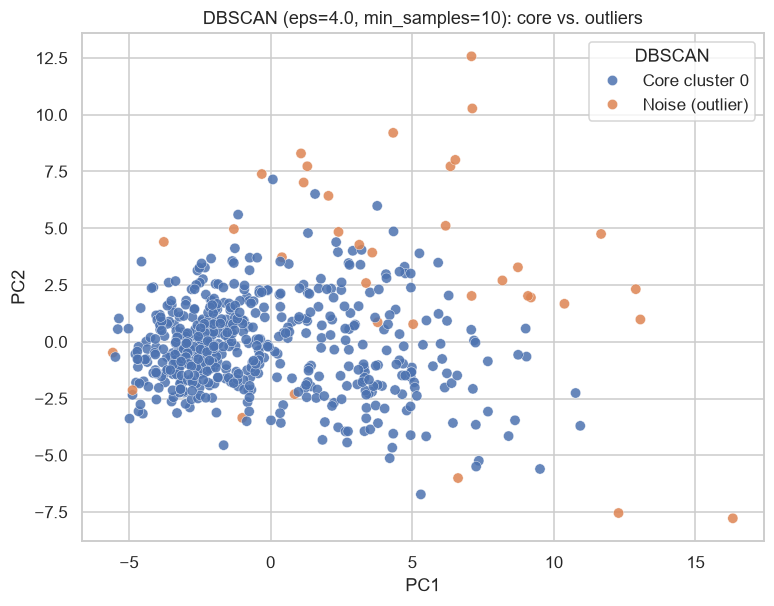

In [18]:
candidates = db_sweep[db_sweep["noise %"] <= 7.0]
best_eps = float(candidates.iloc[0]["eps"])
best_ms = min_samples
print(f"Chosen DBSCAN parameters -> eps = {best_eps}, min_samples = {best_ms}")

db = DBSCAN(eps=best_eps, min_samples=best_ms).fit(X_pca)
db_labels = db.labels_
n_db_clusters = len(set(db_labels)) - (1 if -1 in db_labels else 0)
print(f"Clusters found: {n_db_clusters} | Noise points: {(db_labels == -1).sum()} ({(db_labels == -1).mean()*100:.1f}%)")

df_vis["DBSCAN"] = pd.Categorical(np.where(db_labels == -1, "Noise (outlier)", "Core cluster " + db_labels.astype(str)))
fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(data=df_vis, x="PC1", y="PC2", hue="DBSCAN", s=45, alpha=.85,
                edgecolor="white", linewidth=.3, ax=ax)
ax.set_title(f"DBSCAN (eps={best_eps}, min_samples={best_ms}): core vs. outliers")
save("09_dbscan_2d")
plt.show()

### 6.3 Are the DBSCAN outliers meaningful?

In [19]:
out_tab = pd.crosstab(pd.Series(np.where(db_labels == -1, "Noise (outlier)", "Core"), name="DBSCAN"),
                      y_true.map(target_names).rename("True diagnosis"), normalize="index").mul(100).round(1)
print("Share of each diagnosis (%) inside the core and the outliers:")
out_tab

Share of each diagnosis (%) inside the core and the outliers:


True diagnosis,benign,malignant
DBSCAN,,
Core,64.4,35.6
Noise (outlier),38.9,61.1


In [20]:
px.scatter_3d(df_vis, x="PC1", y="PC2", z="PC3", color="DBSCAN",
              title="DBSCAN: Interactive 3D PCA Projection", opacity=0.8, height=650
              ).update_traces(marker=dict(size=4)).show()

## 7. Hierarchical (Agglomerative) Clustering
### 7.1 Dendrogram (Ward linkage)

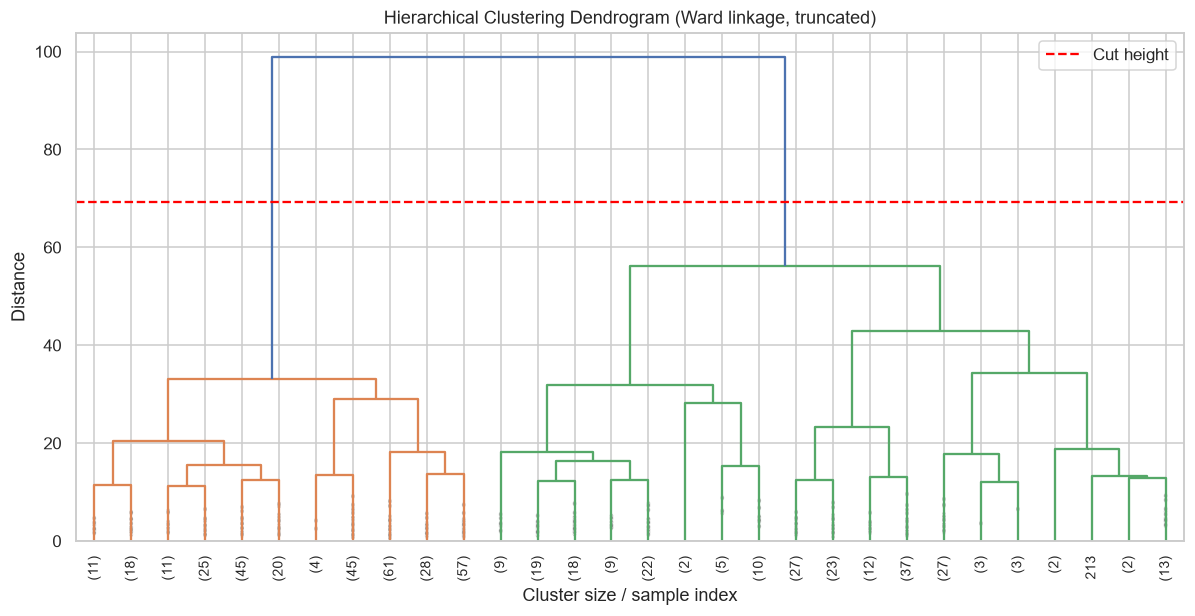

In [21]:
Z = linkage(X_pca, method="ward")

plt.figure(figsize=(13, 6))
dendrogram(Z, truncate_mode="lastp", p=30, leaf_rotation=90, leaf_font_size=9,
           show_contracted=True, color_threshold=0.7 * max(Z[:, 2]))
plt.axhline(y=0.7 * max(Z[:, 2]), color="red", ls="--", label="Cut height")
plt.title("Hierarchical Clustering Dendrogram (Ward linkage, truncated)")
plt.xlabel("Cluster size / sample index"); plt.ylabel("Distance"); plt.legend()
save("10_dendrogram")
plt.show()

### 7.2 Choosing the linkage method and number of clusters
Single, complete and average linkage often score a high Silhouette by splitting off just a couple of outliers. The table below shows the size of the smallest cluster so such degenerate solutions are easy to spot. **Ward linkage** gives balanced, compact clusters, so we use it with the same k as K-Means.

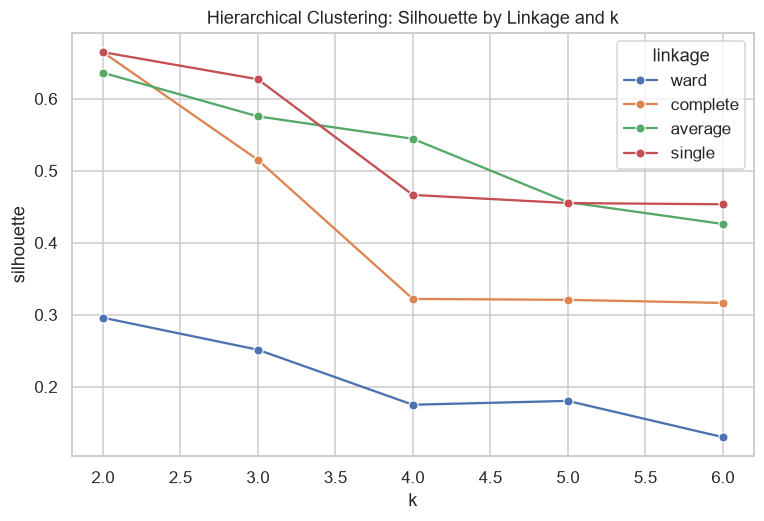

Highest raw silhouette : complete, k=2, score=0.665, smallest cluster = 0.4%  <- degenerate (isolates outliers)
Best valid solution    : ward, k=2, score=0.296, smallest cluster = 42.9%


,linkage,k,silhouette,smallest cluster %
15,single,2,0.665,0.351
5,complete,2,0.665,0.351
10,average,2,0.636,0.527
16,single,3,0.627,0.176
11,average,3,0.576,0.351
12,average,4,0.544,0.176
6,complete,3,0.515,0.351
17,single,4,0.466,0.176


In [22]:
rows = []
for link in ["ward", "complete", "average", "single"]:
    for k in range(2, 7):
        lab = AgglomerativeClustering(n_clusters=k, linkage=link).fit_predict(X_pca)
        rows.append({"linkage": link, "k": k, "silhouette": silhouette_score(X_pca, lab),
                     "smallest cluster %": np.bincount(lab).min() / len(lab) * 100})
hc_grid = pd.DataFrame(rows)

plt.figure(figsize=(8, 5))
sns.lineplot(data=hc_grid, x="k", y="silhouette", hue="linkage", marker="o")
plt.title("Hierarchical Clustering: Silhouette by Linkage and k")
save("11_hierarchical_linkage_comparison")
plt.show()

# Highest raw silhouette vs. highest silhouette among non-degenerate solutions (smallest cluster >= 5%)
raw_best = hc_grid.loc[hc_grid["silhouette"].idxmax()]
valid = hc_grid[hc_grid["smallest cluster %"] >= 5]
valid_best = valid.loc[valid["silhouette"].idxmax()]
print(f"Highest raw silhouette : {raw_best['linkage']}, k={int(raw_best['k'])}, "
      f"score={raw_best['silhouette']:.3f}, smallest cluster = {raw_best['smallest cluster %']:.1f}%  <- degenerate (isolates outliers)")
print(f"Best valid solution    : {valid_best['linkage']}, k={int(valid_best['k'])}, "
      f"score={valid_best['silhouette']:.3f}, smallest cluster = {valid_best['smallest cluster %']:.1f}%")
hc_grid.round(3).sort_values("silhouette", ascending=False).head(8)

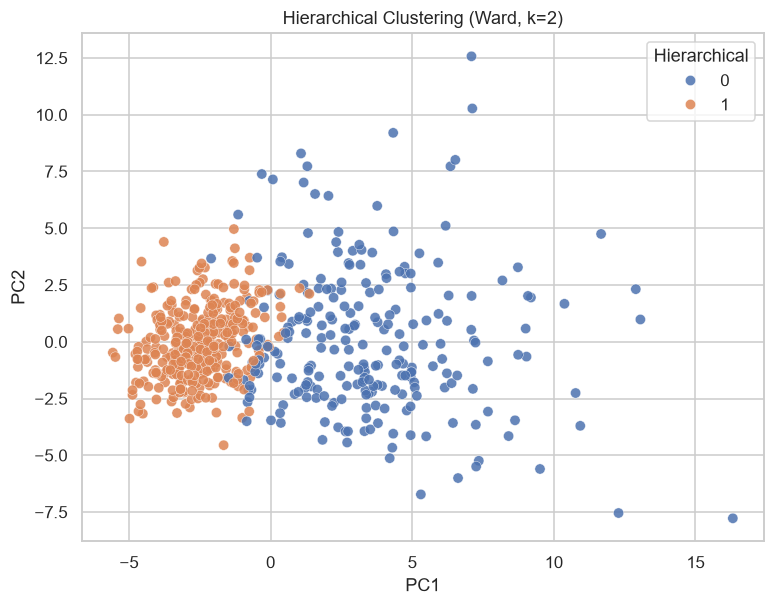

In [23]:
# Use Ward linkage with the same k as K-Means for a fair, interpretable comparison
hc = AgglomerativeClustering(n_clusters=best_k, linkage="ward").fit(X_pca)
hc_labels = hc.labels_
df_vis["Hierarchical"] = pd.Categorical(hc_labels.astype(str))

fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(data=df_vis, x="PC1", y="PC2", hue="Hierarchical", s=45, alpha=.85,
                edgecolor="white", linewidth=.3, ax=ax)
ax.set_title(f"Hierarchical Clustering (Ward, k={best_k})")
save("12_hierarchical_2d")
plt.show()

In [24]:
px.scatter_3d(df_vis, x="PC1", y="PC2", z="PC3", color="Hierarchical",
              title="Hierarchical: Interactive 3D PCA Projection", opacity=0.8, height=650
              ).update_traces(marker=dict(size=4)).show()

## 8. Model Comparison
Internal metrics (need no labels):
* **Silhouette**: higher is better (max 1). Shown as NaN for DBSCAN because it found only one cluster, and the metric needs at least two
* **Davies-Bouldin**: lower is better
* **Calinski-Harabasz**: higher is better

External metric (uses the hidden true diagnosis):
* **Adjusted Rand Index (ARI)**: 1 = perfect match with true classes, 0 = random

In [25]:
def evaluate(name, labels):
    mask = labels != -1                      # ignore DBSCAN noise for internal metrics
    n_cl = len(set(labels[mask]))
    row = {"Algorithm": name, "Clusters": n_cl, "Noise points": int((~mask).sum())}
    if n_cl >= 2:
        row["Silhouette"] = round(silhouette_score(X_pca[mask], labels[mask]), 4)
        row["Davies-Bouldin"] = round(davies_bouldin_score(X_pca[mask], labels[mask]), 4)
        row["Calinski-Harabasz"] = round(calinski_harabasz_score(X_pca[mask], labels[mask]), 1)
    else:                                    # metrics are undefined for a single cluster
        row["Silhouette"] = row["Davies-Bouldin"] = row["Calinski-Harabasz"] = np.nan
    row["ARI vs true diagnosis"] = round(adjusted_rand_score(y_true, labels), 4)   # noise counted as its own group
    return row

results = pd.DataFrame([
    evaluate("K-Means", km_labels),
    evaluate("DBSCAN", db_labels),
    evaluate("Hierarchical (Ward)", hc_labels),
]).set_index("Algorithm")
results

,Clusters,Noise points,Silhouette,Davies-Bouldin,Calinski-Harabasz,ARI vs true diagnosis
Algorithm,,,,,,
K-Means,2,0,0.358,1.2597,288.1,0.6707
DBSCAN,1,36,NaN,NaN,NaN,0.0317
Hierarchical (Ward),2,0,0.296,1.3805,244.1,0.7019


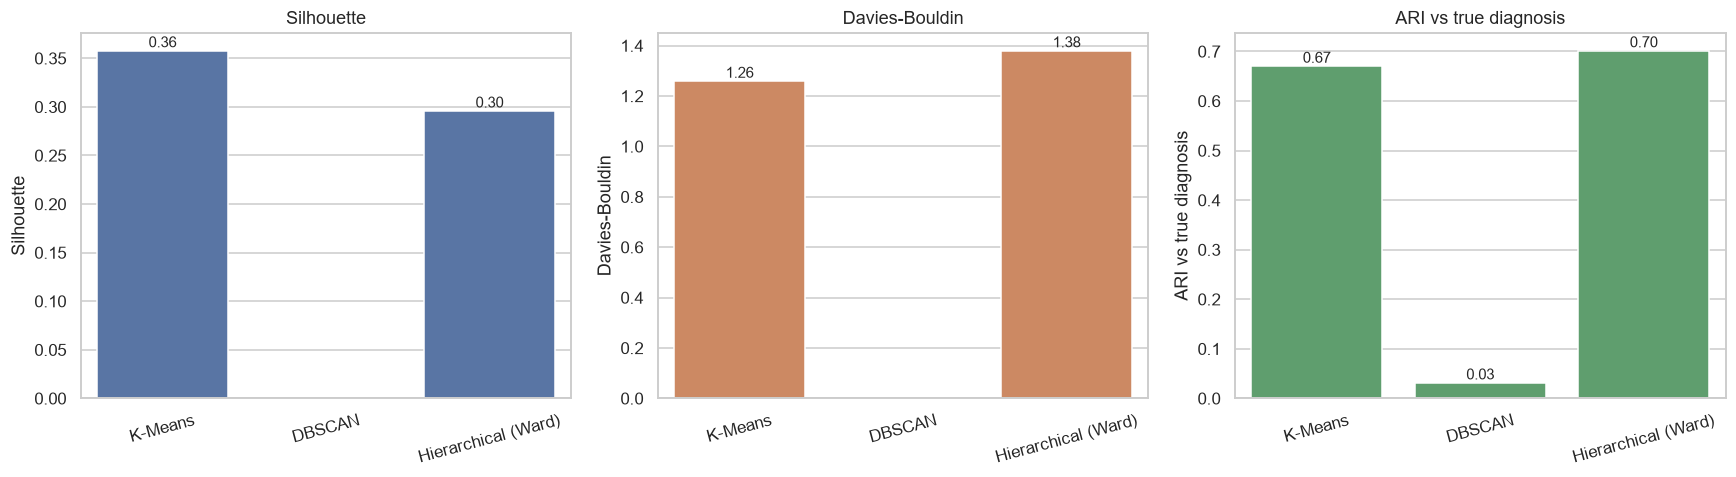

In [26]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for a, metric, c in zip(ax, ["Silhouette", "Davies-Bouldin", "ARI vs true diagnosis"],
                        ["#4c72b0", "#dd8452", "#55a868"]):
    sns.barplot(x=results.index, y=results[metric], color=c, ax=a)
    a.set_title(metric); a.set_xlabel(""); a.tick_params(axis="x", rotation=15)
    for p in a.patches:
        if not np.isnan(p.get_height()):
            a.annotate(f"{p.get_height():.2f}", (p.get_x() + p.get_width() / 2, p.get_height()),
                       ha="center", va="bottom", fontsize=10)
plt.tight_layout()
save("13_model_comparison")
plt.show()

### Cluster vs. true diagnosis (cross-tabulation)

In [27]:
for name, lab in [("K-Means", km_labels), ("Hierarchical", hc_labels)]:
    print(f"\n{name}")
    print(pd.crosstab(pd.Series(lab, name="Cluster"), y_true.map(target_names).rename("True diagnosis")))


K-Means
True diagnosis  benign  malignant
Cluster                          
0                  343         37
1                   14        175

Hierarchical
True diagnosis  benign  malignant
Cluster                          
0                   39        205
1                  318          7


## 9. Conclusions

1. **Standardization** was essential because the 30 features have very different scales.
2. **PCA** compressed 30 correlated features into a much smaller set of components that retain at least 95% of the variance. PC1 acts as a *size and irregularity* axis.
3. **K-Means:** the Elbow curve is ambiguous, but the Silhouette score clearly peaks at k = 2.
4. **DBSCAN** found one dense core plus a small set of outliers. No `eps` value separated the two diagnosis groups, because they overlap and are not divided by a density gap. This is a genuine finding: DBSCAN suits outlier detection on this data better than group separation, and its low ARI should be read that way. Interestingly, the outliers it flags are about 61% malignant versus about 36% in the core, so they are not random noise.
5. **Hierarchical clustering** gives a full cluster tree (dendrogram). Ward linkage produced results very close to K-Means. Other linkages can score a high Silhouette by isolating a few outliers, so a good score must always be checked against cluster sizes.
6. Without ever seeing the diagnosis labels, K-Means and Ward clustering recover the real malignant and benign groups reasonably well (see the ARI values and the cross-tabulation above), which shows that PCA plus clustering can discover meaningful structure in high-dimensional data.
7. A high Silhouette score alone does not guarantee a useful clustering. Always combine internal metrics, cluster sizes, visual inspection and, where available, external validation.

**Possible extensions:** t-SNE or UMAP for non-linear projections, Gaussian Mixture Models, and a Streamlit dashboard for interactive exploration.